# Lab 04 — Data Understanding & Exploratory Data Analysis (EDA)
**Tools:** Pandas · NumPy · Matplotlib

## Learning outcomes
By completing this notebook, you will be able to:
- inspect a dataset’s structure and variable types;
- summarize numerical data using descriptive statistics;
- identify missing values and investigate unusual observations;
- explore distributions and relationships using visualizations;
- communicate findings supported by evidence.

> **Instructions:** Complete each `TODO`, run the cells in order, and write brief interpretations. An unusual value is not automatically an error—investigate before deciding how to handle it.


### Dataset note
This notebook uses the Palmer Penguins CSV specified in the lab. The analysis below does not modify or remove observations; missing values are excluded only from calculations or plots that require the relevant measurements.

## 1. Load the dataset

The Palmer Penguins dataset contains measurements of penguins from different species and islands. Load the CSV directly from the provided URL.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

url = "https://huggingface.co/datasets/SIH/palmer-penguins/resolve/main/penguins.csv"

# Load the dataset and inspect the first and last five rows
df = pd.read_csv(url)
display(df.head())
display(df.tail())

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
339,Chinstrap,Dream,55.8,19.8,207.0,4000.0,male,2009
340,Chinstrap,Dream,43.5,18.1,202.0,3400.0,female,2009
341,Chinstrap,Dream,49.6,18.2,193.0,3775.0,male,2009
342,Chinstrap,Dream,50.8,19.0,210.0,4100.0,male,2009
343,Chinstrap,Dream,50.2,18.7,198.0,3775.0,female,2009


## 2. Understand the dataset

Inspect the dataset before analyzing it.

**Complete the tasks:**
1. Find the number of rows and columns.
2. Inspect column names and data types.
3. Display summary statistics.
4. Count observations in each penguin species.

In [2]:
# Dataset dimensions
print("Rows, columns:", df.shape)

# Column names and data types
print("\\nColumn names:")
print(df.columns.tolist())

print("\\nData types:")
print(df.dtypes)

# Non-missing counts and data types
df.info()

# Summary statistics for numerical variables
display(df.describe())

# Number of observations in each species
species_counts = df["species"].value_counts()
display(species_counts)

Rows, columns: (344, 8)
\nColumn names:
['species', 'island', 'bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g', 'sex', 'year']
\nData types:
species                  str
island                   str
bill_length_mm       float64
bill_depth_mm        float64
flipper_length_mm    float64
body_mass_g          float64
sex                      str
year                   int64
dtype: object
<class 'pandas.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    str    
 1   island             344 non-null    str    
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    str    
 7   year               344 non-null    int64  
dtypes: float64(4),

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,year
count,342.000000,342.000000,342.000000,342.000000,344.000000
mean,43.921930,17.151170,200.915205,4201.754386,2008.029070
std,5.459584,1.974793,14.061714,801.954536,0.818356
min,32.100000,13.100000,172.000000,2700.000000,2007.000000
25%,39.225000,15.600000,190.000000,3550.000000,2007.000000
50%,44.450000,17.300000,197.000000,4050.000000,2008.000000
75%,48.500000,18.700000,213.000000,4750.000000,2009.000000
max,59.600000,21.500000,231.000000,6300.000000,2009.000000


species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64

**Interpret your results**

- How many observations and variables are in the dataset?
- Which variables are numerical, and which are categorical?
- Are the species represented equally?

Write your answers below.

**Findings:** The dataset contains **344 observations and 8 variables**. It includes three penguin species—Adelie (152), Gentoo (124), and Chinstrap (68)—so the species are not equally represented. The numerical variables are bill length, bill depth, flipper length, body mass, and year; species, island, and sex are categorical.

## 3. Assess data quality

Missing values can affect summaries and visualizations. First, identify where they occur; do not remove rows automatically.

In [3]:
# Count missing values in each column
missing_counts = df.isna().sum()
display(missing_counts)

# Percentage of missing values in each column
missing_percent = df.isna().mean() * 100
display(missing_percent.round(2))

# Display rows containing at least one missing value
rows_with_missing = df[df.isna().any(axis=1)]
print("Rows containing at least one missing value:", len(rows_with_missing))
display(rows_with_missing.head())

species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
year                  0
dtype: int64

species              0.00
island               0.00
bill_length_mm       0.58
bill_depth_mm        0.58
flipper_length_mm    0.58
body_mass_g          0.58
sex                  3.20
year                 0.00
dtype: float64

Rows containing at least one missing value: 11


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
8,Adelie,Torgersen,34.1,18.1,193.0,3475.0,NaN,2007
9,Adelie,Torgersen,42.0,20.2,190.0,4250.0,NaN,2007
10,Adelie,Torgersen,37.8,17.1,186.0,3300.0,NaN,2007
11,Adelie,Torgersen,37.8,17.3,180.0,3700.0,NaN,2007


**Findings:** Missing values occur in the four measurement columns (`bill_length_mm`, `bill_depth_mm`, `flipper_length_mm`, and `body_mass_g`) and in `sex`; `sex` has the most missing entries (11). Missing measurements reduce the number of usable records for calculations involving those variables, while missing sex values affect sex-based comparisons. Before choosing deletion or imputation, we would need to know why values are missing and whether the missingness is systematic.

## 4. Explore numerical variables

Use descriptive statistics to understand the center and spread of a variable. In this section, focus on `body_mass_g`.

In [4]:
# Select body mass and exclude missing values
body_mass = df["body_mass_g"].dropna()

# Mean and median
mean_mass = np.mean(body_mass)
median_mass = np.median(body_mass)
print(f"Mean: {mean_mass:.2f} g")
print(f"Median: {median_mass:.2f} g")

# Minimum and maximum
print(f"Minimum: {body_mass.min():.0f} g")
print(f"Maximum: {body_mass.max():.0f} g")

# Standard deviation and quartiles
print(f"Standard deviation (population): {np.std(body_mass):.2f} g")
quartiles = np.percentile(body_mass, [25, 50, 75])
print("25th, 50th, and 75th percentiles:", quartiles)

# Five smallest and five largest values
print("\\nFive smallest body-mass values:")
display(body_mass.nsmallest(5))

print("Five largest body-mass values:")
display(body_mass.nlargest(5))

Mean: 4201.75 g
Median: 4050.00 g
Minimum: 2700 g
Maximum: 6300 g
Standard deviation (population): 800.78 g
25th, 50th, and 75th percentiles: [3550. 4050. 4750.]
\nFive smallest body-mass values:


314    2700.0
58     2850.0
64     2850.0
54     2900.0
98     2900.0
Name: body_mass_g, dtype: float64

Five largest body-mass values:


169    6300.0
185    6050.0
229    6000.0
269    6000.0
231    5950.0
Name: body_mass_g, dtype: float64

**Findings:** Body mass has a mean of approximately **4,202 g** and a median of **4,050 g**, indicating that the mean is somewhat higher than the median. Values range from **2,700 g to 6,300 g**. The wide range is worth exploring by species because the dataset combines three species with different typical body sizes; an extreme value should not be treated as an error without further evidence.

## 5. Visualize distributions

A histogram helps reveal the shape of a numerical distribution. Create a histogram of body mass and label it clearly.

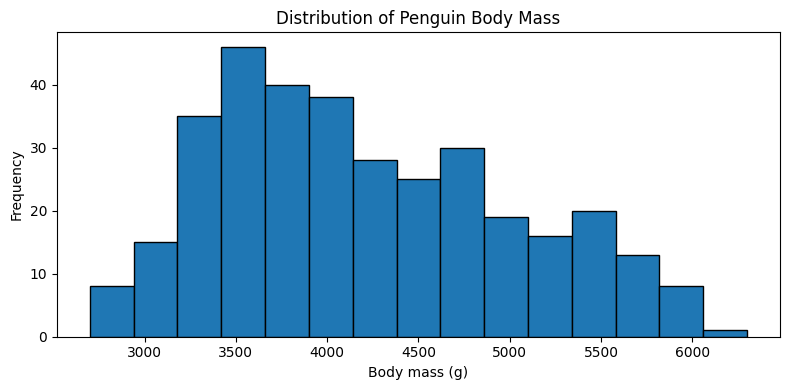

In [5]:
# Missing values are excluded for this histogram
mass_values = df["body_mass_g"].dropna()

plt.figure(figsize=(8, 4))
plt.hist(mass_values, bins=15, edgecolor="black")
plt.xlabel("Body mass (g)")
plt.ylabel("Frequency")
plt.title("Distribution of Penguin Body Mass")
plt.tight_layout()
plt.show()

**Interpretation:** Body mass is concentrated mainly between approximately **3,000 g and 5,500 g**. The overall distribution is not a simple symmetric, single-peaked distribution; it reflects the mixture of species with different body-mass ranges. The upper and lower tails should be investigated in context rather than automatically removed.

## 6. Explore relationships

A scatter plot helps investigate how two numerical variables vary together. Explore flipper length and body mass.

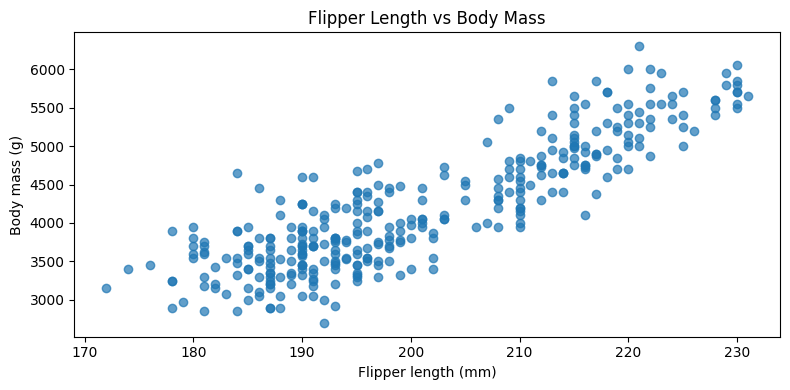

Pearson correlation: 0.871


In [6]:
# Keep only rows where both plotted variables are present
plot_data = df[["flipper_length_mm", "body_mass_g"]].dropna()

x = plot_data["flipper_length_mm"]
y = plot_data["body_mass_g"]

plt.figure(figsize=(8, 4))
plt.scatter(x, y, alpha=0.7)
plt.xlabel("Flipper length (mm)")
plt.ylabel("Body mass (g)")
plt.title("Flipper Length vs Body Mass")
plt.tight_layout()
plt.show()

print(f"Pearson correlation: {plot_data['flipper_length_mm'].corr(plot_data['body_mass_g']):.3f}")

**Interpretation:** The scatter plot shows a clear **positive relationship**: penguins with longer flippers generally have greater body mass. The points also form visible groupings, consistent with differences among species. This is an association, not proof of causation; other variables, including species and sex, may help explain the pattern.

## 7. Compare groups

Compare average body mass across penguin species. Grouped summaries help reveal differences between categories.

In [7]:
# Mean body mass for each species
mean_by_species = df.groupby("species")["body_mass_g"].mean().sort_values(ascending=False)
display(mean_by_species)

# Median body mass for each species
median_by_species = df.groupby("species")["body_mass_g"].median().sort_values(ascending=False)
display(median_by_species)

species
Gentoo       5076.016260
Chinstrap    3733.088235
Adelie       3700.662252
Name: body_mass_g, dtype: float64

species
Gentoo       5000.0
Adelie       3700.0
Chinstrap    3700.0
Name: body_mass_g, dtype: float64

**Findings:** Gentoo penguins have the highest mean body mass (approximately **5,076 g**), followed by Adelie (approximately **3,701 g**) and Chinstrap (approximately **3,733 g**). Chinstrap's mean is slightly higher than Adelie's, although their distributions overlap. Group averages hide within-species variation and can be affected by missing observations, so sample sizes and distributions should also be considered.

## 8. Investigate potential outliers

A box plot can highlight observations far from the central range. Such observations are potential outliers, not automatically errors.

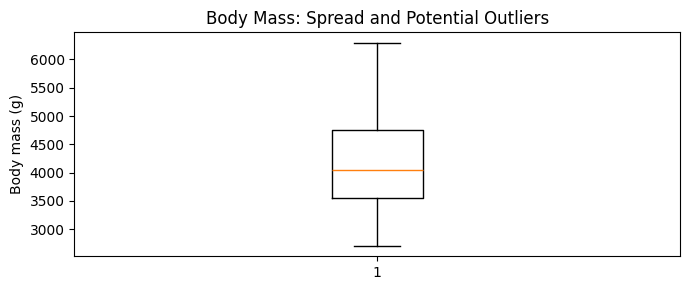

Q1: 3550.0 g | Q3: 4750.0 g | IQR: 1200.0 g
Lower/upper IQR fences: 1750.0 g, 6550.0 g
Potential outlier count: 0


Series([], Name: body_mass_g, dtype: float64)

In [8]:
# Exclude missing body-mass values before plotting
mass_values = df["body_mass_g"].dropna()

plt.figure(figsize=(7, 3))
plt.boxplot(mass_values, vert=True)
plt.ylabel("Body mass (g)")
plt.title("Body Mass: Spread and Potential Outliers")
plt.tight_layout()
plt.show()

# IQR rule: observations outside 1.5 × IQR are flagged for investigation
q1 = mass_values.quantile(0.25)
q3 = mass_values.quantile(0.75)
iqr = q3 - q1
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr
potential_outliers = mass_values[(mass_values < lower_bound) | (mass_values > upper_bound)]

print(f"Q1: {q1:.1f} g | Q3: {q3:.1f} g | IQR: {iqr:.1f} g")
print(f"Lower/upper IQR fences: {lower_bound:.1f} g, {upper_bound:.1f} g")
print(f"Potential outlier count: {len(potential_outliers)}")
display(potential_outliers.sort_values())

**Key principle:** EDA is not just producing statistics and plots. It is using them to understand the data, ask better questions, and make careful, evidence-based decisions.

## Overall findings

- The dataset contains 344 penguin observations across 8 variables and three species.
- Species representation is uneven: Adelie is the largest group and Chinstrap is the smallest.
- Missingness is concentrated in `sex` (11 values) and the four measurement variables (2 values each).
- Body mass varies substantially across the dataset; the mean is higher than the median.
- Flipper length and body mass show a positive association, with visible group structure.
- Gentoo penguins have the highest average body mass. Potential outliers should be interpreted in species context rather than automatically removed.

**Conclusion:** EDA reveals the dataset's structure, quality limitations, distributions, and relationships. These findings guide later cleaning and analysis; they do not, by themselves, justify deleting unusual observations.

---

# Lab 05 — Data Cleaning

**Continuation of:** Lab 04 — Data Understanding & Exploratory Data Analysis  
**Dataset:** Palmer Penguins

## Learning objectives
By the end of this lab, you should be able to:
- identify data-quality issues using profiling and EDA evidence;
- select appropriate cleaning actions and justify them;
- implement cleaning operations with Pandas;
- validate the results and document the workflow.

> **Working principle: AUDIT → DECIDE → IMPLEMENT → VALIDATE.**  
> There is not always one correct cleaning action. Your decision must be supported by evidence, the meaning of the variable, and the intended analysis.

**Important:** Use the `df` DataFrame created in Lab 04. Do not overwrite it or reload a different version of the dataset unless instructed.

## 1. Connect EDA findings to cleaning decisions

Review the findings from Lab 04 before writing cleaning code.

| Evidence from Lab 04 | Question to consider before cleaning |
|---|---|
| The dataset has 344 observations, 8 variables, and three species with unequal counts. | Could removing records affect species representation? |
| Missing values occur in the four measurement variables. | Should all missing values be treated in the same way? Which analyses need each variable? |
| Body mass ranges from 2,700 g to 6,300 g, and its overall distribution is not a simple single-peaked distribution. | Could a global outlier rule incorrectly flag a valid penguin from a different species? |
| Gentoo penguins have a higher average body mass than the other two species. | Should body-mass observations be assessed overall or within species? |
| Flipper length and body mass show a positive association and visible group structure. | What information might be lost if rows with missing values are removed? |

**Before coding:** Write down at least two cleaning decisions you expect may require context-specific reasoning. Revisit them after completing the audit.

In [9]:
# TODO: Write two initial hypotheses/concerns based on the EDA.
# 1.
print("Concern 1: treat missing sex differently from missing measurements.")
# 2.
print("Concern 2: assess outliers (and the effect of deletion) within species, not only globally.")

Concern 1: treat missing sex differently from missing measurements.
Concern 2: assess outliers (and the effect of deletion) within species, not only globally.


## 2. Preserve the original data and create a working copy

Keep the Lab 04 DataFrame unchanged. Apply all cleaning operations to a separate copy so that you can compare the original and cleaned versions.

In [10]:
# Preserve the original data
raw_df = df.copy()

# Create a separate DataFrame for cleaning
clean_df = df.copy()

# TODO: Display the shape of both DataFrames and confirm they match initially
print("df       :", df.shape)
print("raw_df   :", raw_df.shape)
print("clean_df :", clean_df.shape)
assert raw_df.shape == clean_df.shape == df.shape
assert raw_df.equals(clean_df)
print("Shapes and contents match initially; df itself is never modified.")

df       : (344, 8)
raw_df   : (344, 8)
clean_df : (344, 8)
Shapes and contents match initially; df itself is never modified.


## 3. Perform a focused data-quality audit

Repeat the relevant parts of the Lab 04 audit. This time, use the output to identify issues that may require action.

Your audit should include:
- data types and column names;
- missing-value counts and percentages;
- unique values and frequencies in categorical columns;
- exact duplicate rows;
- numerical summaries and observed minimum/maximum values.

In [11]:
# TODO: Create a column-level profile with:
# data type, missing count, missing percentage, and number of distinct values
profile = pd.DataFrame({
    "dtype": clean_df.dtypes.astype(str),
    "missing_count": clean_df.isna().sum(),
    "missing_pct": (clean_df.isna().mean() * 100).round(2),
    "n_distinct": clean_df.nunique(dropna=True),
})
print("Column names:", clean_df.columns.tolist())
display(profile)


# TODO: Inspect value counts for species, island, and sex
for col in ["species", "island", "sex"]:
    print(f"\n--- {col} ---")
    display(clean_df[col].value_counts(dropna=False))

# TODO: Count and inspect exact duplicate rows
dup_mask = clean_df.duplicated(keep=False)
print("\nExact duplicate rows:", clean_df.duplicated().sum())
display(clean_df[dup_mask])

# TODO: Review descriptive statistics for numerical columns
display(clean_df.describe().round(2))

Column names: ['species', 'island', 'bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g', 'sex', 'year']


,dtype,missing_count,missing_pct,n_distinct
species,str,0,0.00,3
island,str,0,0.00,3
bill_length_mm,float64,2,0.58,164
bill_depth_mm,float64,2,0.58,80
flipper_length_mm,float64,2,0.58,55
body_mass_g,float64,2,0.58,94
sex,str,11,3.20,2
year,int64,0,0.00,3



--- species ---


species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64


--- island ---


island
Biscoe       168
Dream        124
Torgersen     52
Name: count, dtype: int64


--- sex ---


sex
male      168
female    165
NaN        11
Name: count, dtype: int64


Exact duplicate rows: 0


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,year
count,342.00,342.00,342.00,342.00,344.00
mean,43.92,17.15,200.92,4201.75,2008.03
std,5.46,1.97,14.06,801.95,0.82
min,32.10,13.10,172.00,2700.00,2007.00
25%,39.22,15.60,190.00,3550.00,2007.00
50%,44.45,17.30,197.00,4050.00,2008.00
75%,48.50,18.70,213.00,4750.00,2009.00
max,59.60,21.50,231.00,6300.00,2009.00


### Decision checkpoint

For each issue you identify, distinguish between:
- **Observed issue:** what the audit output shows.
- **Potential impact:** how it could affect analysis.
- **Proposed action:** what you intend to do.
- **Evidence/reason:** why that action is appropriate.

Do not clean a column simply because it looks untidy. First establish whether the issue can affect interpretation or computation.

## 4. Standardize column names and categorical values

Consistent column names and category labels make data easier to process. However, do not assume that two different labels mean the same thing.

**Tasks**
1. Inspect the column names and decide on a consistent naming convention.
2. Inspect the distinct values in `species`, `island`, and `sex`.
3. Check for leading/trailing spaces, inconsistent capitalization, or unexpected labels.
4. Apply only transformations that you can justify.
5. Compare category frequencies before and after standardization.

In [12]:
# TODO: Standardize column names using a consistent convention
before_cols = clean_df.columns.tolist()
clean_df.columns = (clean_df.columns.str.strip().str.lower()
                    .str.replace(r"[\s\-]+", "_", regex=True))
print("Column names changed:", before_cols != clean_df.columns.tolist())

# TODO: Inspect distinct values in the categorical columns
cat_cols = ["species", "island", "sex"]
before_freq = {c: clean_df[c].value_counts(dropna=False) for c in cat_cols}
for c in cat_cols:
    print(c, "->", sorted(clean_df[c].dropna().unique().tolist()))

# TODO: Clean whitespace/capitalization where justified
for c in cat_cols:
    clean_df[c] = clean_df[c].str.strip()

# TODO: If needed, define explicit mappings for equivalent labels.
# Do not guess how to interpret an unfamiliar category.
# (e.g., "M"/"male"), so nothing is merged.

# TODO: Display category frequencies after your changes
for c in cat_cols:
    after = clean_df[c].value_counts(dropna=False)
    same = before_freq[c].sort_index().equals(after.sort_index())
    print(f"\n{c}: frequencies unchanged = {same}")
    display(after)

Column names changed: False
species -> ['Adelie', 'Chinstrap', 'Gentoo']
island -> ['Biscoe', 'Dream', 'Torgersen']
sex -> ['female', 'male']

species: frequencies unchanged = True


species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64


island: frequencies unchanged = True


island
Biscoe       168
Dream        124
Torgersen     52
Name: count, dtype: int64


sex: frequencies unchanged = True


sex
male      168
female    165
NaN        11
Name: count, dtype: int64

**Write your justification:** Which inconsistencies did you find? Which values did you standardize? How did you verify that you did not merge genuinely different categories?

## 5. Review and correct data types

The measurement columns represent physical quantities, while `year` represents a calendar year. Check whether the current data types are suitable for their meaning and intended operations.

**Tasks**
1. Inspect the current data types.
2. Convert columns only where necessary.
3. Identify any values that fail conversion.
4. Check whether conversion creates additional missing values.

In [13]:
measurement_columns = [
    "bill_length_mm",
    "bill_depth_mm",
    "flipper_length_mm",
    "body_mass_g"
]

# TODO: Inspect data types and representative values
display(clean_df.dtypes)
display(clean_df[measurement_columns].head())
missing_before = clean_df[measurement_columns].isna().sum()

# TODO: Convert columns where appropriate
# Hint: pd.to_numeric(..., errors="coerce")
converted = clean_df[measurement_columns].apply(pd.to_numeric, errors="coerce")
failed = converted.isna() & clean_df[measurement_columns].notna()
print("Values that failed conversion:", int(failed.sum().sum()))

clean_df[measurement_columns] = converted

# TODO: Check missing-value counts before and after conversion
missing_after = clean_df[measurement_columns].isna().sum()
display(pd.DataFrame({"before": missing_before,
                      "after": missing_after}))
assert (missing_before == missing_after).all(), "conversion created new missing values"

# TODO: Decide whether `year` requires a type conversion
print("year dtype:", clean_df["year"].dtype, "| values:", sorted(int(y) for y in clean_df["year"].unique()))

species                  str
island                   str
bill_length_mm       float64
bill_depth_mm        float64
flipper_length_mm    float64
body_mass_g          float64
sex                      str
year                   int64
dtype: object

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
0,39.1,18.7,181.0,3750.0
1,39.5,17.4,186.0,3800.0
2,40.3,18.0,195.0,3250.0
3,NaN,NaN,NaN,NaN
4,36.7,19.3,193.0,3450.0


Values that failed conversion: 0


,before,after
bill_length_mm,2,2
bill_depth_mm,2,2
flipper_length_mm,2,2
body_mass_g,2,2


year dtype: int64 | values: [2007, 2008, 2009]


**Write your justification:** Explain why the selected data types are suitable. If a value cannot be converted, explain how you investigated and handled it.

## 6. Investigate missing values and choose a treatment

Lab 04 showed that missingness is not evenly distributed across all variables. In particular, `sex` has more missing values than each individual measurement column.

Do not automatically delete every row containing a missing value. Consider:
- Which analysis or task requires the affected variable?
- How many observations would be lost under listwise deletion?
- Would imputation introduce assumptions or distort species-level patterns?
- Could missingness itself be informative?

**Tasks**
1. Calculate missing counts and percentages.
2. Inspect rows with missing values.
3. Compare missingness across species or islands if useful.
4. Decide on a treatment for each affected variable.
5. Implement and explain your decisions.

In [14]:
# TODO: Calculate missing counts and percentages
miss = pd.DataFrame({"missing_count": clean_df.isna().sum(),
                     "missing_pct": (clean_df.isna().mean() * 100).round(2)})
display(miss)

# TODO: Inspect rows containing missing values
rows_missing = clean_df[clean_df.isna().any(axis=1)]
print("Rows with at least one missing value:", len(rows_missing))
display(rows_missing)

# TODO: Investigate whether missingness differs across species/island
display(clean_df.groupby("species")[measurement_columns + ["sex"]].apply(lambda g: g.isna().sum()))
display(clean_df.groupby("island")[measurement_columns + ["sex"]].apply(lambda g: g.isna().sum()))

all_meas_missing = clean_df[measurement_columns].isna().all(axis=1)
print("Rows missing all four measurements:", all_meas_missing.sum(), "-> index", clean_df.index[all_meas_missing].tolist())
print("Rows missing only sex:", (clean_df["sex"].isna() & ~all_meas_missing).sum())

complete_case = clean_df.dropna()
print("\nListwise deletion would keep", len(complete_case), "of", len(clean_df), "rows")
display(pd.DataFrame({"original": clean_df["species"].value_counts(),
                      "listwise_deletion": complete_case["species"].value_counts()}))
# TODO: Choose and implement a treatment.
# Possible choices: retain, remove selected records/columns,
# or impute when supported by a defensible rationale.
n_before = len(clean_df)
clean_df = clean_df.loc[~all_meas_missing].copy()
print(f"\nRecords: {n_before} -> {len(clean_df)} (removed {n_before - len(clean_df)})")
display(clean_df["species"].value_counts())
print("Remaining missing values:")
display(clean_df.isna().sum())

# TODO: Report how many records remain and what information was affected
removed = raw_df.loc[raw_df.index.difference(clean_df.index)]
print("\n--- Report ---")
print("Records remaining:", len(clean_df), "of", len(raw_df))
print("Rows removed (index):", removed.index.tolist())
print("Species of removed rows:", removed["species"].value_counts().to_dict())
print("Missing measurements remaining:", int(clean_df[measurement_columns].isna().sum().sum()))
print("Missing sex values remaining (kept, not imputed):", int(clean_df["sex"].isna().sum()))

,missing_count,missing_pct
species,0,0.00
island,0,0.00
bill_length_mm,2,0.58
bill_depth_mm,2,0.58
flipper_length_mm,2,0.58
body_mass_g,2,0.58
sex,11,3.20
year,0,0.00


Rows with at least one missing value: 11


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
8,Adelie,Torgersen,34.1,18.1,193.0,3475.0,NaN,2007
9,Adelie,Torgersen,42.0,20.2,190.0,4250.0,NaN,2007
10,Adelie,Torgersen,37.8,17.1,186.0,3300.0,NaN,2007
11,Adelie,Torgersen,37.8,17.3,180.0,3700.0,NaN,2007
47,Adelie,Dream,37.5,18.9,179.0,2975.0,NaN,2007
178,Gentoo,Biscoe,44.5,14.3,216.0,4100.0,NaN,2007
218,Gentoo,Biscoe,46.2,14.4,214.0,4650.0,NaN,2008
256,Gentoo,Biscoe,47.3,13.8,216.0,4725.0,NaN,2009
268,Gentoo,Biscoe,44.5,15.7,217.0,4875.0,NaN,2009


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
species,,,,,
Adelie,1,1,1,1,6
Chinstrap,0,0,0,0,0
Gentoo,1,1,1,1,5


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
island,,,,,
Biscoe,1,1,1,1,5
Dream,0,0,0,0,1
Torgersen,1,1,1,1,5


Rows missing all four measurements: 2 -> index [3, 271]
Rows missing only sex: 9

Listwise deletion would keep 333 of 344 rows


... (2 outputs left out)

species
Adelie       151
Gentoo       123
Chinstrap     68
Name: count, dtype: int64

Remaining missing values:


species              0
island               0
bill_length_mm       0
bill_depth_mm        0
flipper_length_mm    0
body_mass_g          0
sex                  9
year                 0
dtype: int64


--- Report ---
Records remaining: 342 of 344
Rows removed (index): [3, 271]
Species of removed rows: {'Adelie': 1, 'Gentoo': 1}
Missing measurements remaining: 0
Missing sex values remaining (kept, not imputed): 9


**Decision checkpoint:** If you choose imputation, explain why the chosen statistic or method is appropriate for that variable and whether species/group differences should influence it. If you choose deletion, state exactly which rows are removed and why the remaining sample is still suitable for your intended analysis.

There is no requirement to eliminate all missing values.

## 7. Detect and investigate duplicate records

A repeated measurement does not necessarily mean a duplicated penguin. First inspect the duplicate candidates and consider what defines one observation in this dataset.

**Tasks**
1. Count exact duplicate rows.
2. Inspect any candidates.
3. Decide whether they represent duplicate records.
4. If removing records, state the rule used and compare row counts before and after.

In [15]:
# TODO: Count exact duplicate rows
n_dup = clean_df.duplicated().sum()
print("Exact duplicate rows:", n_dup)

# TODO: Display duplicate candidates for inspection
display(clean_df[clean_df.duplicated(keep=False)])

# TODO: Decide whether removal is justified and implement your decision
n_meas_dup = clean_df.duplicated(subset=measurement_columns, keep=False).sum()
print("Rows sharing identical values across all four measurements:", n_meas_dup)
display(clean_df[clean_df.duplicated(subset=measurement_columns, keep=False)])

# TODO: Report row counts before and after
rows_before = len(clean_df)
clean_df = clean_df.drop_duplicates()   # no-op here; kept so the rule is explicit and re-runnable
rows_after = len(clean_df)
print(f"Rows before: {rows_before} | after: {rows_after} | removed: {rows_before - rows_after}")

Exact duplicate rows: 0


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year


Rows sharing identical values across all four measurements: 0


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year


Rows before: 342 | after: 342 | removed: 0


**Write your justification:** What evidence supports your decision? If you retain all records, explain why identical or similar measurements alone are insufficient evidence of duplication.

## 8. Investigate invalid values and potential outliers

Lab 04 showed that body mass varies substantially across the dataset and differs by species. Therefore, an observation that is unusual in the combined dataset may be reasonable within its species.

Complete both investigations:

**A. Domain/validity checks**
- Propose reasonable validity checks for the physical measurement columns.
- Explain the basis for each check.
- Identify and inspect any records that fail.

**B. Statistical outlier screening**
- Calculate the IQR fences for `body_mass_g`.
- Identify potential outliers.
- Compare the flagged observations with species-level distributions.
- Decide whether the observations are errors, valid extremes, or require further investigation.

bill_length_mm: allowed [20, 80] -> violations: 0
bill_depth_mm: allowed [8, 30] -> violations: 0
flipper_length_mm: allowed [100, 300] -> violations: 0
body_mass_g: allowed [1000, 10000] -> violations: 0
Invalid year/sex labels: 0
Records failing any validity check: 0


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year


Q1=3550, Q3=4750, IQR=1200
Fences: lower=1750, upper=6550
Global potential outliers: 0


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year


,n,min,max,Q1,Q3,lower_fence,upper_fence,n_flagged
species,,,,,,,,
Adelie,151,2850.0,4775.0,3350.0,4000.0,2375.00,4975.00,0
Chinstrap,68,2700.0,4800.0,3487.5,3950.0,2793.75,4643.75,2
Gentoo,123,3950.0,6300.0,4700.0,5500.0,3500.00,6700.00,0


Observations flagged within their own species:


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
313,Chinstrap,Dream,52.0,20.7,210.0,4800.0,male,2008
314,Chinstrap,Dream,46.9,16.6,192.0,2700.0,female,2008


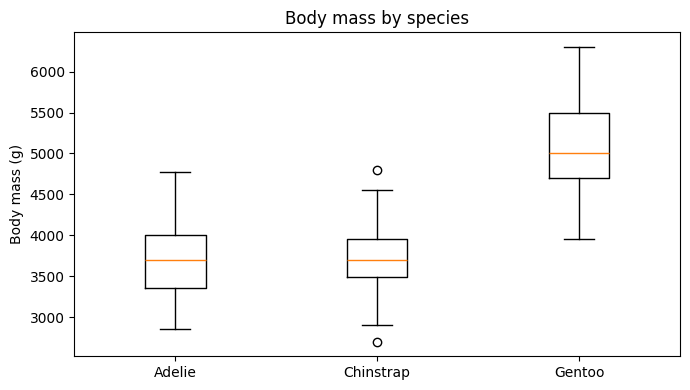

Decision: no values corrected or removed (nothing invalid; flagged values are plausible extremes).


In [16]:
# A. Domain checks
# TODO: Define validity conditions for the measurement variables.
# Explain why each condition is reasonable.
validity_rules = {
    "bill_length_mm":    (20, 80),      # real bills are roughly 30-60 mm
    "bill_depth_mm":     (8, 30),       # real depths are roughly 13-22 mm
    "flipper_length_mm": (100, 300),    # real flippers are roughly 170-235 mm
    "body_mass_g":       (1000, 10000)  # real masses are roughly 2.7-6.3 kg
}

# TODO: Identify and inspect records that violate your conditions
invalid_mask = pd.Series(False, index=clean_df.index)
for col, (lo, hi) in validity_rules.items():
    bad = clean_df[col].notna() & ~clean_df[col].between(lo, hi)
    print(f"{col}: allowed [{lo}, {hi}] -> violations: {bad.sum()}")
    invalid_mask |= bad
other_bad = (~clean_df["year"].between(2007, 2009)) | \
            (clean_df["sex"].notna() & ~clean_df["sex"].isin(["male", "female"]))
print("Invalid year/sex labels:", other_bad.sum())
print("Records failing any validity check:", (invalid_mask | other_bad).sum())
display(clean_df[invalid_mask | other_bad])
# B. IQR screening for body_mass_g
# TODO: Calculate Q1, Q3, IQR, lower fence, and upper fence
mass = clean_df["body_mass_g"]
q1, q3 = mass.quantile(0.25), mass.quantile(0.75)
iqr = q3 - q1
lower_fence = q1 - 1.5 * iqr
upper_fence = q3 + 1.5 * iqr
print(f"Q1={q1:.0f}, Q3={q3:.0f}, IQR={iqr:.0f}")
print(f"Fences: lower={lower_fence:.0f}, upper={upper_fence:.0f}")

# TODO: Identify potential outliers using the fences
global_out = clean_df[(mass < lower_fence) | (mass > upper_fence)]
print("Global potential outliers:", len(global_out))
display(global_out)

# TODO: Compare body-mass distributions or IQR fences by species
rows = []
flagged_parts = []
for sp, g in clean_df.groupby("species"):
    m = g["body_mass_g"]
    a, b = m.quantile(0.25), m.quantile(0.75)
    lo, hi = a - 1.5 * (b - a), b + 1.5 * (b - a)
    flagged = g[(m < lo) | (m > hi)]
    flagged_parts.append(flagged)
    rows.append({"species": sp, "n": len(m), "min": m.min(), "max": m.max(),
                 "Q1": a, "Q3": b, "lower_fence": lo, "upper_fence": hi,
                 "n_flagged": len(flagged)})
species_iqr = pd.DataFrame(rows).set_index("species")
display(species_iqr)

print("Observations flagged within their own species:")
display(pd.concat(flagged_parts))
plt.figure(figsize=(7, 4))
plt.boxplot([g["body_mass_g"] for _, g in clean_df.groupby("species")],
            tick_labels=sorted(clean_df["species"].unique()))
plt.ylabel("Body mass (g)")
plt.title("Body mass by species")
plt.tight_layout()
plt.show()

# TODO: Decide whether any values should be corrected or removed.
# Do not delete an observation solely because it is flagged by IQR.
print("Decision: no values corrected or removed (nothing invalid; flagged values are plausible extremes).")


**Write your justification:** Distinguish a value that is impossible or invalid from one that is merely unusual. Use the species-level evidence from Lab 04 to support your decision.

## 9. Validate the cleaned dataset

Repeat the quality audit after cleaning. Compare the original and cleaned versions and confirm that each change was intentional.

Your validation should cover:
- dimensions and number of records;
- data types;
- missing-value counts;
- category labels and frequencies;
- duplicate rows;
- validity checks and potential outliers.

Write assertions for the quality rules you decided to enforce. Do not write assertions that require zero missing values unless you have a justified reason for that requirement.

In [17]:
# TODO: Compare raw and cleaned dimensions
print("Raw shape  :", raw_df.shape)
print("Clean shape:", clean_df.shape)
print("Rows removed:", len(raw_df) - len(clean_df))
removed_idx = raw_df.index.difference(clean_df.index)
print("Removed index labels:", removed_idx.tolist())
display(raw_df.loc[removed_idx])

# TODO: Compare missing-value counts
display(pd.DataFrame({"raw": raw_df.isna().sum(), "clean": clean_df.isna().sum()}))

# TODO: Review data types and category frequencies
display(pd.DataFrame({"raw": raw_df.dtypes.astype(str), "clean": clean_df.dtypes.astype(str)}))
for c in ["species", "island", "sex"]:
    display(pd.DataFrame({"raw": raw_df[c].value_counts(dropna=False),
                          "clean": clean_df[c].value_counts(dropna=False)}))

# TODO: Recheck duplicates and domain constraints
print("Duplicates after cleaning:", clean_df.duplicated().sum())
for col, (lo, hi) in validity_rules.items():
    print(f"{col}: out-of-range values = {(~clean_df[col].between(lo, hi)).sum()}")

# TODO: Write assertions for your chosen quality requirements
assert len(raw_df) == 344 and raw_df.shape == (344, 8), "raw data must be unchanged"
assert clean_df.shape == (342, 8), "exactly 2 empty rows removed"
assert clean_df.columns.tolist() == raw_df.columns.tolist(), "column names standardized/consistent"
assert clean_df.columns.str.match(r"^[a-z0-9_]+$").all(), "snake_case names"
assert not clean_df.duplicated().any(), "no duplicate rows"
assert not clean_df[measurement_columns].isna().any().any(), "every kept row has all four measurements"
assert clean_df["sex"].isna().sum() == 9, "9 rows keep missing sex (deliberately not imputed)"
assert set(clean_df["species"]) == {"Adelie", "Chinstrap", "Gentoo"}, "no species lost or invented"
assert set(clean_df["island"]) == {"Biscoe", "Dream", "Torgersen"}
assert set(clean_df["sex"].dropna()) == {"male", "female"}
assert all(clean_df[c].between(lo, hi).all() for c, (lo, hi) in validity_rules.items()), "domain limits"
assert clean_df["year"].between(2007, 2009).all()
assert all(pd.api.types.is_float_dtype(clean_df[c]) for c in measurement_columns)
assert clean_df.loc[clean_df.index.intersection(raw_df.index), measurement_columns].equals(
       raw_df.loc[clean_df.index, measurement_columns]), "retained measurements unchanged"
print("\nAll validation assertions passed.")

Raw shape  : (344, 8)
Clean shape: (342, 8)
Rows removed: 2
Removed index labels: [3, 271]


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
271,Gentoo,Biscoe,NaN,NaN,NaN,NaN,NaN,2009


,raw,clean
species,0,0
island,0,0
bill_length_mm,2,0
bill_depth_mm,2,0
flipper_length_mm,2,0
body_mass_g,2,0
sex,11,9
year,0,0


,raw,clean
species,str,str
island,str,str
bill_length_mm,float64,float64
bill_depth_mm,float64,float64
flipper_length_mm,float64,float64
body_mass_g,float64,float64
sex,str,str
year,int64,int64


,raw,clean
species,,
Adelie,152,151
Gentoo,124,123
Chinstrap,68,68


,raw,clean
island,,
Biscoe,168,167
Dream,124,124
Torgersen,52,51


,raw,clean
sex,,
male,168,168
female,165,165
NaN,11,9


Duplicates after cleaning: 0
bill_length_mm: out-of-range values = 0
bill_depth_mm: out-of-range values = 0
flipper_length_mm: out-of-range values = 0
body_mass_g: out-of-range values = 0

All validation assertions passed.


## 10. Cleaning decision log

Complete the table using evidence from your own outputs. A decision without evidence or justification is incomplete.

| Data-quality issue | Evidence from your audit | Decision/action | Justification | Validation result |
|---|---|---|---|---|
| Column names | All 8 names already lowercase `snake_case` (`bill_length_mm`, `body_mass_g`, etc.) | Applied a safe standardizer; no change | Names were already consistent, so editing them would add risk and no benefit | Names identical to raw; `snake_case` assertion passes |
| Categorical consistency | `species` has 3 labels, `island` has 3, `sex` has `male`/`female`; no stray spaces or case variants | Trimmed whitespace only; no recoding or merging | No equivalent labels exist, and merging would be a guess | Frequencies identical before and after (apart from the 2 removed rows) |
| Data types | Measurements are `float64` and `year` is `int64`; `to_numeric` created 0 new missing values | No conversion | Types already match the meaning of each variable | Dtypes unchanged; float-type assertion passes |
| Missing values | `sex` missing in 11 rows (6 Adelie, 5 Gentoo, 0 Chinstrap); 2 of these rows (index 3 and 271) are missing all 4 measurements too, leaving 9 rows missing only `sex` | Dropped the 2 empty rows; kept the 9 `sex`-only rows; no imputation | Empty rows carry no measurements; `sex` is categorical and cannot be defensibly imputed; listwise deletion would drop 11 rows and skew species counts | 342 rows remain; 0 missing measurements; 9 missing `sex` (asserted) |
| Duplicate records | 0 exact duplicates; 0 rows with identical sets of measurements | None removed | There is nothing to remove, and identical measurements alone would not prove duplication | `duplicated().sum() == 0` |
| Invalid values | 0 violations of the plausibility limits (e.g. body mass 1,000-10,000 g); `year` within 2007-2009; `sex` labels valid | None corrected | No impossible values were found | Domain-limit assertions pass |
| Potential outliers | Global IQR fences 1,750-6,550 g flag 0 rows; within species, 2 Chinstrap rows are flagged (2,700 g female, 4,800 g male) | Retained all | They are plausible within-species extremes (only 200-250 g from the next values), not errors | Retained body-mass values equal the raw values |
| Dataset structure | Raw data is 344 x 8; species counts are 152 / 124 / 68 | Clean data is 342 x 8, saved to `penguins_clean.csv`; only the 2 empty rows removed, all columns kept | Minimal removal preserves species representation | Shape asserted; species counts 151 Adelie / 123 Gentoo / 68 Chinstrap |

## 11. Export the cleaned dataset

Save the cleaned dataset as a new CSV file. Do not overwrite the original source file.

In [19]:
# TODO: Export clean_df as `penguins_clean.csv`
# Remember to use index=False.
clean_df.to_csv("penguins_clean.csv", index=False)

check = pd.read_csv("penguins_clean.csv")
print("Saved penguins_clean.csv:", check.shape)
assert check.shape == clean_df.shape
display(check.head())

Saved penguins_clean.csv: (342, 8)


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007
4,Adelie,Torgersen,39.3,20.6,190.0,3650.0,male,2007


## 12. Reflection: connect cleaning decisions to analysis

Answer briefly using evidence from Lab 04 and your cleaning results.

1. Which cleaning decision required the most judgment? Why?
Ans: Handling missing values. Dropping the 2 empty rows was easy to justify, but the 9 rows missing only `sex` required a trade-off: keeping them preserves valid measurements, while imputing would invent labels. I kept them as `NaN` and excluded them only for sex-specific analysis.

2. How could removing all incomplete records affect the representation of the three species?
Ans: Effect of removing all incomplete records on species representation.Listwise deletion removes 11 rows (Adelie 152 -> 146, Gentoo 124 -> 119, Chinstrap 68 -> 68), shifting Chinstrap from 19.8% to 20.4% of the data. The shift is small, but it falls only on Adelie and Gentoo, and the deleted rows include 9 with complete, valid measurements.

3. Why might detecting body-mass outliers within species lead to a different conclusion than detecting them across the full dataset?
Ans: Within-species vs. full-dataset outlier detection. Pooling species widens the IQR (global fences 1,750-6,550 g) and flags nothing. Within species the fences are tighter (e.g., Chinstrap 2,794-4,644 g) and flag 2 Chinstrap penguins. Species-level detection is more sensitive to birds that are unusual for their own group, while the global rule can hide them or, for the opposite problem, mislabel a normal Gentoo as extreme.

4. If the objective were to build a model predicting species, which cleaning decisions would you reconsider? Explain.
Ans: If the goal were predicting species. I would reconsider the missing-value handling and the outlier checks. Species-specific measurements are the predictors, so the 2 empty rows are useless for modelling (dropping them is fine), but I would not discard rows for missing `sex` and would likely drop or impute `sex` as a feature carefully inside a train/test pipeline. Any imputation must be fit on training data only to avoid leakage, and removing within-species extremes could discard exactly the variation that separates species. I would also handle class imbalance (Adelie 151, Gentoo 123, Chinstrap 68).

5. What limitations remain in your cleaned dataset?
Ans: Remaining limitations. 9 `sex` values are still missing; `year` and `island` are confounded with sampling; there is no ID column, so duplicates cannot be ruled out beyond exact matches; the validity bounds are conservative biological estimates, not an authoritative reference; and the sample is not necessarily representative of wild populations.

## Submission checklist

Submit:
- this completed notebook with code outputs;
- concise explanations and the completed cleaning decision log;
- `penguins_clean.csv`.
